In [2]:
# !pip install pytorch-lightning wandb 

In [12]:
import os, sys, gc 
from pathlib import Path
from typing import Dict, List, Tuple, Optional
import numpy as np
import pandas as pd
import math

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from torch.optim import AdamW

import onnxruntime as ort
import matplotlib.pyplot as plt

import pytorch_lightning as pl
import wandb

import warnings
warnings.filterwarnings("ignore")

print("pytorch version:", torch.__version__)
print("onnxruntime version:", ort.__version__)

pytorch version: 2.1.0.post100
onnxruntime version: 1.23.2


In [ ]:
sys.path.append('/Users/ime/Work/WunderNN-Predictorium/src')

from utils import DataPoint, ScorerStepByStep

# Config

In [50]:
from dataclasses import dataclass

@dataclass
class config():
    exp: str = "exp01"
    
    # Data
    ROOT = Path('/Users/ime/Work/WunderNN-Predictorium')
    train_file: Path = ROOT / "datasets/train.parquet"
    test_file: Path = ROOT / "datasets/valid.parquet"
    test_size: float = 0.1 #0.2

    output_dir: Path = ROOT / "solutions" / exp
    
    # Model
    # input_dim: int = 10
    output_dim: int = 2
    cnn_hidden_dim: int = 64
    gru_hidden_dim: int = 128
    gru_layers: int = 1
    transformer_dim: int = 128
    transformer_heads: int = 4
    transformer_layers: int = 2
    transformer_dropout: float = 0.1

    # Training
    batch_size: int = 64
    epochs: int = 20
    lr: float = 2e-4
    weight_decay: float = 1e-4
    seed: int = 42
    
    # Misc
    debug: bool = True

In [51]:
cfg = config()

In [26]:
cfg

config(train_file=PosixPath('/Users/ime/Work/WunderNN-Predictorium/datasets/train.parquet'), test_file=PosixPath('/Users/ime/Work/WunderNN-Predictorium/datasets/valid.parquet'), test_size=0.1, output_dim=2, cnn_hidden_dim=64, gru_hidden_dim=128, gru_layers=1, transformer_dim=128, transformer_heads=4, transformer_layers=2, transformer_dropout=0.1, batch_size=64, epochs=20, lr=0.0002, weight_decay=0.0001, seed=42, debug=True)

# Data

In [27]:
train_data = pd.read_parquet(cfg.train_file)
valid_data = pd.read_parquet(cfg.test_file)

# Calc feature dimension: first 3 columns are seq_ix, step_in_seq & need_prediction
# Total columns: 3 metadata + 32 features + 2 targets = 37
# Features are cols [3:35]
dim = 2
FEATURES = train_data.columns[3:35].tolist()
TARGETS  = train_data.columns[35:].tolist()

In [7]:
TARGETS

['t0', 't1']

In [9]:
train_data

,seq_ix,step_in_seq,need_prediction,p0,p1,p2,p3,p4,p5,p6,...,dp0,dp1,dp2,dp3,dv0,dv1,dv2,dv3,t0,t1
0,0,0,0,1.077446,-0.710366,0.373591,0.835558,0.050204,-0.139710,1.367384,...,-0.031078,-0.053527,-0.475214,-0.410787,0.805692,0.516635,-0.368215,-0.503497,-0.564226,1.864018
1,0,1,0,1.100140,-0.562796,0.483658,0.875354,0.138444,-0.010037,1.354714,...,0.950145,-0.083598,-0.604252,-0.703991,-1.925171,1.252957,-1.563974,-1.929990,-0.239079,2.168843
2,0,2,0,1.100140,-0.562796,0.483658,0.875354,0.138444,-0.010037,1.870266,...,-0.168259,1.632066,-0.178565,0.121240,1.377339,1.803970,-0.402838,1.042579,2.237778,2.459723
3,0,3,0,0.955471,-1.486537,0.230353,0.676854,-0.262686,-0.366873,2.011996,...,-0.426942,-0.743530,0.680013,1.394857,0.785266,1.424660,1.258192,0.914074,1.998699,2.272444
4,0,4,0,1.025123,-0.832006,0.317650,0.759677,-0.062770,-0.230353,2.174650,...,0.195700,0.293986,0.494971,0.267884,-1.315502,1.775372,1.302424,1.355667,1.998699,2.324245
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10720995,10720,995,1,1.025123,-0.832006,0.317650,0.759677,-0.062770,-0.230353,1.218002,...,-0.094232,-0.193143,-0.436240,-0.165095,-0.985610,0.621099,-0.855287,-1.116369,0.086068,0.200428
10720996,10720,996,1,1.025123,-0.832006,0.317650,0.759677,-0.062770,-0.230353,1.218002,...,-0.094232,-0.193143,-0.436240,-0.165095,0.805692,0.516635,-0.368215,-0.503497,0.086068,0.210389
10720997,10720,997,1,1.025123,-0.832006,0.317650,0.759677,-0.062770,-0.230353,1.218002,...,-0.234219,-0.855287,0.520661,0.318969,0.482248,0.132113,0.048948,0.076604,0.086068,0.220351
10720998,10720,998,1,1.025123,-0.832006,0.317650,0.759677,-0.062770,-0.230353,1.218002,...,0.040157,-0.321611,0.408805,-0.273089,-0.181652,-0.181652,-0.181652,-0.181652,0.086068,0.230313


In [10]:
# unique sequences
train_data['seq_ix'].unique()

array([    0,     1,     2, ..., 10718, 10719, 10720])

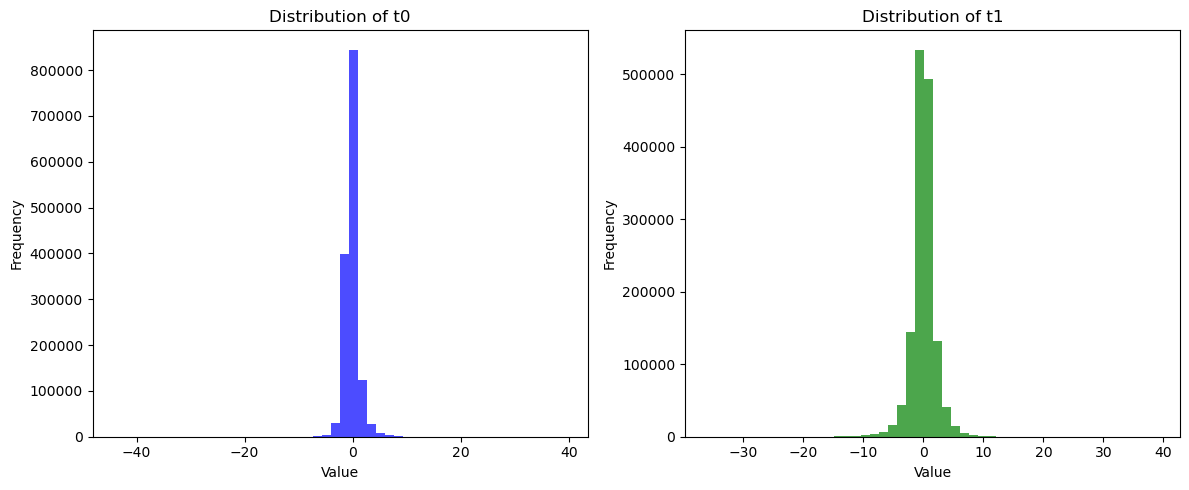

In [ ]:
# visualize targets distribution

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(val_data[targets[0]], bins=50, color='blue', alpha=0.7)
plt.title(f'Distribution of {targets[0]}')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.subplot(1, 2, 2)
plt.hist(val_data[targets[1]], bins=50, color='green', alpha=0.7)
plt.title(f'Distribution of {targets[1]}')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [31]:
def visualize_targets_over_time(dataset, seq_ix):
    seq_data = dataset[dataset['seq_ix'] == seq_ix]

    plt.figure(figsize=(15, 10))
    plt.subplot(len(unique_seqs), 1, i + 1)
    plt.plot(seq_data['step_in_seq'], seq_data['t0'], label='t0', color='blue')
    plt.plot(seq_data['step_in_seq'], seq_data['t1'], label='t1', color='green')
    
    # add a needed_prediction marker as vertical line
    need_pred_steps = seq_data[seq_data['need_prediction'] == True]['step_in_seq'].values[:1]
    for step in need_pred_steps:
        plt.axvline(x=step, color='red', linestyle='--', label='Need Prediction')

    plt.title(f'[Sequence {seq_ix}] Targets')
    plt.xlabel('Step')
    plt.ylabel('Target')
    plt.legend()

In [28]:
val_data['seq_ix'].unique()

array([   0,    1,    2, ..., 1441, 1442, 1443])

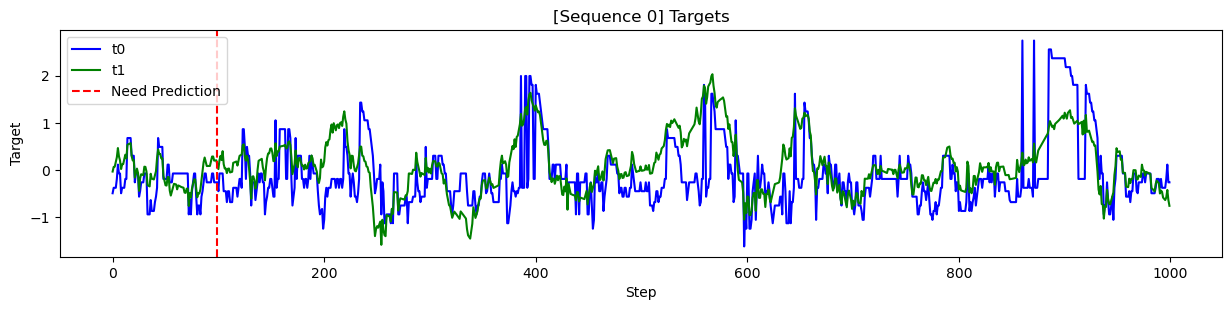

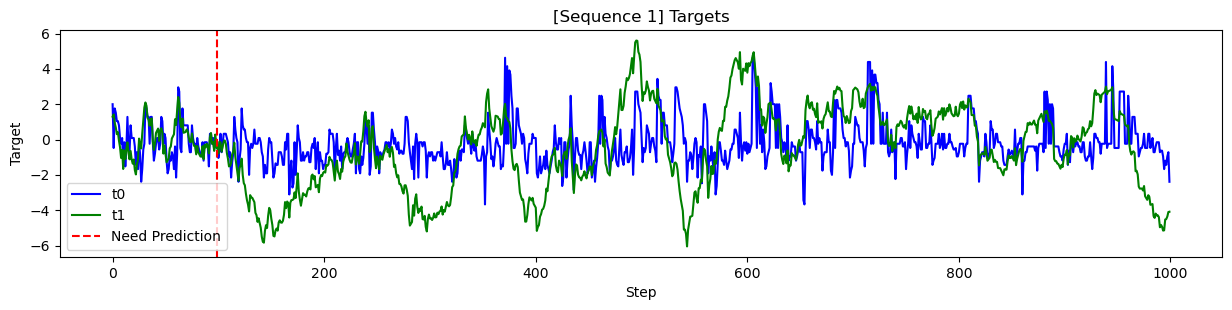

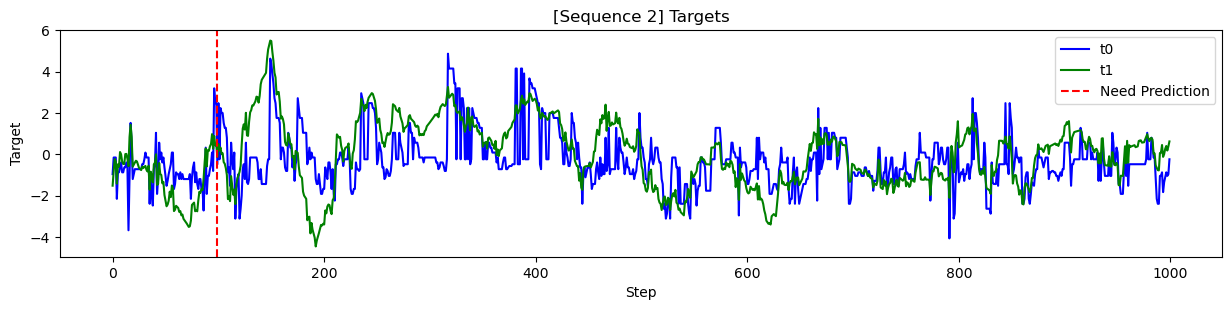

In [32]:
# visualize targets over time for a few sequences
unique_seqs = val_data['seq_ix'].unique()[:3]  # Take first 3 unique sequences

for i, seq_ix in enumerate(unique_seqs):
    visualize_targets_over_time(val_data, seq_ix)

# Dataset

In [28]:
import os
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader, random_split
import pytorch_lightning as pl


class SequenceDataset(Dataset):
    def __init__(self,
        df: pd.DataFrame,
        feature_cols: List[str],
        target_cols: List[str],
        seq_ids: List[int],
        feature_mean: np.ndarray | None = None,
        feature_std: np.ndarray | None = None,
    ):
        """
        Each item is a full sequence of shape (T, F).
        We also return a mask for positions where need_prediction=True.
        """
        self.df = df
        self.feature_cols = feature_cols
        self.target_cols = target_cols
        self.seq_ids = seq_ids

        # Build index: seq_ix -> (feature_tensor, target_tensor, mask_tensor)
        self.sequences: Dict[int, Dict[str, torch.Tensor]] = {}

        # Pre-compute feature stats if not provided
        if feature_mean is None or feature_std is None:
            feat_values = df[feature_cols].values.astype(np.float32)
            feature_mean = feat_values.mean(axis=0)
            feature_std = feat_values.std(axis=0) + 1e-6

        self.feature_mean = feature_mean
        self.feature_std = feature_std

        for seq in seq_ids:
            sdf = df[df["seq_ix"] == seq].sort_values("step_in_seq")
            feats = sdf[feature_cols].values.astype(np.float32)
            targets = sdf[target_cols].values.astype(np.float32)
            need_pred = sdf["need_prediction"].values.astype(bool)

            feats = (feats - self.feature_mean) / self.feature_std

            self.sequences[seq] = {
                "features": torch.from_numpy(feats),          # (T, F)
                "targets": torch.from_numpy(targets),         # (T, 2)
                "mask": torch.from_numpy(need_pred),          # (T,)
            }

        self.seq_ix_list = list(self.sequences.keys())

    def __len__(self):
        return len(self.seq_ix_list)

    def __getitem__(self, idx: int):
        seq_id = self.seq_ix_list[idx]
        item = self.sequences[seq_id]
        return (
            item["features"],   # (T, F)
            item["targets"],    # (T, 2)
            item["mask"].bool() # (T,)
        )



In [10]:
def check_dataset():
    dataset = SequenceDataset(
        df=train_data,
        feature_cols=FEATURES,
        target_cols=TARGETS,
        seq_ids=train_data['seq_ix'].unique().tolist()
    )
    print(f"Dataset size: {len(dataset)} sequences")

    for i in range(1):
        features, targets, mask = dataset[i]
        print(f"Sequence {i}:")
        print(f"  Features shape: {features.shape}")
        print(f"  Targets shape: {targets.shape}")
        print(f"  Mask shape: {mask.shape}")
        print(f"  Mask sum (need_prediction count): {mask.sum().item()}")

### Run the check
check_dataset()

Dataset size: 10721 sequences
Sequence 0:
  Features shape: torch.Size([1000, 32])
  Targets shape: torch.Size([1000, 2])
  Mask shape: torch.Size([1000])
  Mask sum (need_prediction count): 901


In [55]:
def get_dataloaders(cfg: config) -> Tuple[DataLoader, DataLoader]:
    
    # Full dataset
    full_dataset = SequenceDataset(
        df=train_data,
        feature_cols=FEATURES,
        target_cols=TARGETS,
        seq_ids=train_data['seq_ix'].unique().tolist()
    )

    # Split into train/valid
    valid_size = int(len(full_dataset) * cfg.test_size)
    train_size = len(full_dataset) - valid_size
    train_dataset, valid_dataset = random_split(full_dataset, [train_size, valid_size])

    train_loader = DataLoader(train_dataset, batch_size=cfg.batch_size, shuffle=True, )
    valid_loader = DataLoader(valid_dataset, batch_size=cfg.batch_size, shuffle=False,)

    test_dataset = SequenceDataset(
        df=valid_data,
        feature_cols=FEATURES,
        target_cols=TARGETS,
        seq_ids=valid_data['seq_ix'].unique().tolist()
    )
    test_loader = DataLoader(test_dataset, batch_size=cfg.batch_size, shuffle=False,)

    return train_loader, valid_loader, test_loader

In [44]:
def weighted_pearson_correlation(
    y_true: torch.Tensor,
    y_pred: torch.Tensor,
    eps: float = 1e-8,
) -> torch.Tensor:
    """
    y_true, y_pred: (..., 2) last dim = targets
    Implements the same concept as utils.weighted_pearson_correlation in numpy,
    but in PyTorch for monitoring.
    We weight by absolute value of target.
    """
    # Clip predictions
    y_pred = torch.clamp(y_pred, -6.0, 6.0)

    # shape: (N, 2)
    w = torch.abs(y_true)
    w_sum = torch.sum(w, dim=0) + eps

    mean_y = torch.sum(w * y_true, dim=0) / w_sum
    mean_p = torch.sum(w * y_pred, dim=0) / w_sum

    num = torch.sum(w * (y_true - mean_y) * (y_pred - mean_p), dim=0)
    den_y = torch.sqrt(torch.sum(w * (y_true - mean_y) ** 2, dim=0) + eps)
    den_p = torch.sqrt(torch.sum(w * (y_pred - mean_p) ** 2, dim=0) + eps)
    corr = num / (den_y * den_p + eps)
    return corr.mean()


# Model

In [45]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_len: int = 1000):
        super().__init__()
        pe = torch.zeros(max_len, d_model)  # (T, D)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        self.register_buffer("pe", pe.unsqueeze(0))  # (1, T, D)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: (B, T, D)
        T = x.size(1)
        return x + self.pe[:, :T, :]

In [46]:
class CNNGRUTransformer_V1(nn.Module):
    def __init__(self, cfg, input_dim: int, vb: bool = False):
        super().__init__()
        self.cfg = cfg
        self.vb = vb
        self.input_dim = input_dim
        self.output_dim = 2 # Num targets = 2 t0, t1
        self.lr = cfg.lr
        self.weight_decay = cfg.weight_decay

        # 1) CNN encoder (local temporal patterns)
        # Treat time as sequence axis. We'll do Conv1d over time: (B, F, T) -> (B, C, T)
        self.cnn = nn.Sequential(
            nn.Conv1d(input_dim, self.cfg.cnn_hidden_dim, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(self.cfg.cnn_hidden_dim, self.cfg.cnn_hidden_dim, kernel_size=3, padding=1),
            nn.ReLU(),
        )

        # 2) GRU over CNN features
        self.gru = nn.GRU(
            input_size=self.cfg.cnn_hidden_dim,
            hidden_size=self.cfg.gru_hidden_dim,
            num_layers=self.cfg.gru_layers,
            batch_first=True,
            bidirectional=False,
        )

        # 3) Transformer encoder over GRU outputs
        self.pos_encoder = PositionalEncoding(self.cfg.transformer_dim)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=self.cfg.transformer_dim,
            nhead=self.cfg.transformer_heads,
            dim_feedforward=self.cfg.transformer_dim * 4,
            dropout=self.cfg.transformer_dropout,
            batch_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=self.cfg.transformer_layers,
        )

        self.proj_to_transformer_dim = nn.Linear(self.cfg.gru_hidden_dim, self.cfg.transformer_dim)

        # 4) Output head
        self.head = nn.Sequential(
            nn.LayerNorm(self.cfg.transformer_dim),
            nn.Linear(self.cfg.transformer_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 2),
        )

        self.loss_fn = None
        # self.loss_fn = nn.SmoothL1Loss(reduction="none")  # Huber
    

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (B, T, F) normalized features.
        returns: (B, T, 2) predictions
        """
        B, T, F = x.shape
        if self.vb: print(f"Inp shape (B, T, F): {x.shape}")

        # CNN expects (B, F, T)
        x_cnn_in = x.transpose(1, 2)  # (B, F, T)
        if self.vb: print(f"CNN inp shape (B, F, T): {x_cnn_in.shape}")
        x_cnn = self.cnn(x_cnn_in)    # (B, C, T)
        if self.vb: print(f"CNN out shape (B, C, T): {x_cnn.shape}")
        x_cnn = x_cnn.transpose(1, 2) # (B, T, C)
        if self.vb: print(f"CNN out transposed shape (B, T, C): {x_cnn.shape}")

        # GRU
        gru_out, _ = self.gru(x_cnn)  # (B, T, H)
        if self.vb: print(f"GRU out shape (B, T, H): {gru_out.shape}")

        # Transformer
        x_tr = self.proj_to_transformer_dim(gru_out)  # (B, T, D)
        if self.vb: print(f"Proj to transformer dim shape (B, T, D): {x_tr.shape}")
        x_tr = self.pos_encoder(x_tr)
        if self.vb: print(f"Pos enc added shape (B, T, D): {x_tr.shape}")
        x_tr = self.transformer(x_tr)  # (B, T, D)
        if self.vb: print(f"Transformer out shape (B, T, D): {x_tr.shape}")

        out = self.head(x_tr)  # (B, T, 2)
        if self.vb: print(f"Head out shape (B, T, 2): {out.shape}")
        return out

In [32]:
cfg.input_dim = len(FEATURES)
cfg.output_dim = 2

In [47]:
@torch.no_grad()
def check_model():

    model = CNNGRUTransformer_V1(cfg, input_dim=cfg.input_dim, vb=True)
    sample_inp = torch.randn(4, 100, cfg.input_dim)  # (B=4, T=10, F=32)
    sample_target = torch.randn(4, 100, cfg.output_dim)  # (B=4, T=10, F=2)
    
    
    sample_out = model(sample_inp)

    print(f"Sample input shape: {sample_inp.shape}")    # Should be (4, 10, 32)
    print(f"Sample output shape: {sample_out.shape}")  # Should be (4, 10, 2)

    loss_fn = nn.MSELoss()
    
    loss = loss_fn(sample_out, sample_target)
    print(f"loss: {loss.item()}")

    wpr = weighted_pearson_correlation(sample_target, sample_out)
    print(f"Weighted Pearson Correlation: {wpr.item()}")


### Run the model check
check_model()

Inp shape (B, T, F): torch.Size([4, 100, 32])
CNN inp shape (B, F, T): torch.Size([4, 32, 100])
CNN out shape (B, C, T): torch.Size([4, 64, 100])
CNN out transposed shape (B, T, C): torch.Size([4, 100, 64])
GRU out shape (B, T, H): torch.Size([4, 100, 128])
Proj to transformer dim shape (B, T, D): torch.Size([4, 100, 128])
Pos enc added shape (B, T, D): torch.Size([4, 100, 128])
Transformer out shape (B, T, D): torch.Size([4, 100, 128])
Head out shape (B, T, 2): torch.Size([4, 100, 2])
Sample input shape: torch.Size([4, 100, 32])
Sample output shape: torch.Size([4, 100, 2])
loss: 1.1018158197402954
Weighted Pearson Correlation: 0.07067637890577316


In [79]:
# compatible with challenge eval + submit code

class PredictionModel(CNNGRUTransformer_V1):
    def __init__(self):
        super().__init__(cfg, input_dim=len(FEATURES), vb=False)

    def predict(self, data_point: DataPoint) -> np.ndarray:
        features = data_point.state.copy()
        # expand dims to (1, T, F)
        features = torch.from_numpy(features).unsqueeze(0).to(next(self.parameters()).device)
        print(f"Predict input shape: {features.shape}")
        preds = self.forward(features)
        return preds.detach().cpu().numpy()

In [80]:
pred_mdl = PredictionModel()

In [81]:
row = valid_data.iloc[0].values
seq_ix = row[0]
step_in_seq = row[1]
need_prediction = row[2]
lob_data = row[3:35]  # 32 features
labels = row[35:]     # 2 targets
#
data_point = DataPoint(seq_ix, step_in_seq, need_prediction, lob_data)
prediction = pred_mdl.predict(data_point)

print(f"Prediction shape: {prediction.shape}")

Predict input shape: torch.Size([1, 32])


ValueError: not enough values to unpack (expected 3, got 2)

In [ ]:
pred_mdl.predict(data_point)

# Light Engine

In [ ]:
class WunderDataModule(pl.LightningDataModule):
    def __init__(self,
        root_dir: str,
        train_file: str = "datasets/train.parquet",
        batch_size: int = 16,
        num_workers: int = 4,
        val_frac: float = 0.1,
        seed: int = 42,
    ):
        super().__init__()
        self.root_dir = Path(root_dir)
        self.train_file = self.root_dir / train_file
        self.batch_size = batch_size
        self.num_workers = num_workers
        self.val_frac = val_frac
        self.seed = seed

        self.feature_cols: List[str] = []
        self.target_cols: List[str] = ["t0", "t1"]

        self.train_dataset: SequenceDataset | None = None
        self.val_dataset: SequenceDataset | None = None

    def setup(self, stage: str | None = None):
        df = pd.read_parquet(self.train_file)

        # Figure out columns
        # First 3 are: seq_ix, step_in_seq, need_prediction
        all_cols = list(df.columns)
        self.feature_cols = all_cols[3:-2]
        self.target_cols = all_cols[-2:]

        # Get per-feature stats over ALL train data
        feat_values = df[self.feature_cols].values.astype(np.float32)
        feat_mean = feat_values.mean(axis=0)
        feat_std = feat_values.std(axis=0) + 1e-6

        # Split by seq_ix
        seq_ids = df["seq_ix"].unique()
        rng = np.random.RandomState(self.seed)
        rng.shuffle(seq_ids)

        n_val = int(len(seq_ids) * self.val_frac)
        val_ids = seq_ids[:n_val].tolist()
        train_ids = seq_ids[n_val:].tolist()

        self.train_dataset = SequenceDataset(
            df, self.feature_cols, self.target_cols, train_ids,
            feature_mean=feat_mean, feature_std=feat_std,
        )
        self.val_dataset = SequenceDataset(
            df, self.feature_cols, self.target_cols, val_ids,
            feature_mean=self.train_dataset.feature_mean,
            feature_std=self.train_dataset.feature_std,
        )

    def train_dataloader(self):
        return DataLoader(
            self.train_dataset,
            batch_size=self.batch_size,
            shuffle=True,
            num_workers=self.num_workers,
            pin_memory=True,
        )

    def val_dataloader(self):
        return DataLoader(
            self.val_dataset,
            batch_size=self.batch_size,
            shuffle=False,
            num_workers=self.num_workers,
            pin_memory=True,
        )

In [41]:
class WunderModelLight(pl.LightningModule):
    def __init__(self, cfg,
        input_dim: int,
        vb: bool = False,
    ):
        super().__init__()
        self.cfg = cfg
        self.vb = vb
        self.save_hyperparameters()

        self.input_dim = input_dim
        self.lr = self.cfg.lr
        self.weight_decay = self.cfg.weight_decay

        # # 1) CNN encoder (local temporal patterns)
        # # Treat time as sequence axis. We'll do Conv1d over time: (B, F, T) -> (B, C, T)
        # self.cnn = nn.Sequential(
        #     nn.Conv1d(input_dim, cnn_hidden_dim, kernel_size=3, padding=1),
        #     nn.ReLU(),
        #     nn.Conv1d(cnn_hidden_dim, cnn_hidden_dim, kernel_size=3, padding=1),
        #     nn.ReLU(),
        # )

        # # 2) GRU over CNN features
        # self.gru = nn.GRU(
        #     input_size=cnn_hidden_dim,
        #     hidden_size=gru_hidden_dim,
        #     num_layers=gru_layers,
        #     batch_first=True,
        #     bidirectional=False,
        # )

        # # 3) Transformer encoder over GRU outputs
        # self.pos_encoder = PositionalEncoding(transformer_dim)
        # encoder_layer = nn.TransformerEncoderLayer(
        #     d_model=transformer_dim,
        #     nhead=transformer_heads,
        #     dim_feedforward=transformer_dim * 4,
        #     dropout=transformer_dropout,
        #     batch_first=True,
        # )
        # self.transformer = nn.TransformerEncoder(
        #     encoder_layer,
        #     num_layers=transformer_layers,
        # )

        # self.proj_to_transformer_dim = nn.Linear(gru_hidden_dim, transformer_dim)

        # # 4) Output head
        # self.head = nn.Sequential(
        #     nn.LayerNorm(transformer_dim),
        #     nn.Linear(transformer_dim, 64),
        #     nn.ReLU(),
        #     nn.Linear(64, 2),
        # )

        self.model = CNNGRUTransformer_V1(cfg, input_dim=input_dim)

        self.loss_fn = nn.SmoothL1Loss(reduction="none")  # Huber

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (B, T, F) normalized features.
        returns: (B, T, 2) predictions
        """
        B, T, F = x.shape

        # CNN expects (B, F, T)
        x_cnn_in = x.transpose(1, 2)  # (B, F, T)
        x_cnn = self.cnn(x_cnn_in)    # (B, C, T)
        x_cnn = x_cnn.transpose(1, 2) # (B, T, C)

        # GRU
        gru_out, _ = self.gru(x_cnn)  # (B, T, H)

        # Transformer
        x_tr = self.proj_to_transformer_dim(gru_out)  # (B, T, D)
        x_tr = self.pos_encoder(x_tr)
        x_tr = self.transformer(x_tr)  # (B, T, D)

        out = self.head(x_tr)  # (B, T, 2)
        return out

    def _compute_loss_and_metrics(
        self,
        batch,
        stage: str,
    ):
        feats, targets, mask = batch  # feats: (B, T, F), targets: (B, T, 2), mask: (B, T)
        preds = self(feats)

        # Only positions where need_prediction=True
        mask = mask.bool()
        if mask.sum() == 0:
            loss = torch.tensor(0.0, device=self.device, requires_grad=True)
            corr = torch.tensor(0.0, device=self.device)
        else:
            preds_masked = preds[mask]     # (N, 2)
            targets_masked = targets[mask] # (N, 2)

            loss_per = self.loss_fn(preds_masked, targets_masked)  # (N, 2)
            loss = loss_per.mean()

            with torch.no_grad():
                corr = weighted_pearson_correlation(targets_masked, preds_masked)

        self.log(f"{stage}_loss", loss, prog_bar=True, on_step=False, on_epoch=True)
        self.log(f"{stage}_wpcorr", corr, prog_bar=(stage != "train"), on_step=False, on_epoch=True)

        return loss

    def training_step(self, batch, batch_idx):
        return self._compute_loss_and_metrics(batch, "train")

    def validation_step(self, batch, batch_idx):
        self._compute_loss_and_metrics(batch, "val")

    def configure_optimizers(self):
        optimizer = AdamW(self.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode="max", factor=0.5, patience=3, verbose=True
        )
        return {
            "optimizer": optimizer,
            "lr_scheduler": {
                "scheduler": scheduler,
                "monitor": "val_wpcorr",
                "frequency": 1,
            },
        }

# Training

In [54]:
import torch
import pytorch_lightning as pl
from pytorch_lightning.callbacks import ModelCheckpoint, EarlyStopping

cfg.train = True
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")

# def train_model(cfg):

if cfg.train:

    # dm = LOBDataModule(
    #     root_dir=str(root),
    #     train_file="datasets/train.parquet",
    #     batch_size=16,
    #     num_workers=4,
    #     val_frac=0.1,
    #     seed=42,
    # )
    # dm.setup(None)
    input_dim = len(FEATURES)

    train_loader, valid_loader, test_loader = get_dataloaders(cfg)

    model = CNNGRUTransformer(
        input_dim=input_dim,
        cnn_hidden_dim=64,
        gru_hidden_dim=128,
        gru_layers=1,
        transformer_dim=128,
        transformer_heads=4,
        transformer_layers=2,
        transformer_dropout=0.1,
        lr=2e-4,
        weight_decay=1e-4,
    )

    checkpoint_cb = ModelCheckpoint(
        dirpath=str(root / "checkpoints"),
        filename="hybrid-{epoch:02d}-{val_wpcorr:.4f}",
        monitor="val_wpcorr",
        mode="max",
        save_top_k=3,
    )
    early_stop_cb = EarlyStopping(
        monitor="val_wpcorr",
        mode="max",
        patience=8,
        min_delta=1e-4,
    )

    trainer = pl.Trainer(
        default_root_dir=str(cfg.output_dir / "lightning_logs"),
        max_epochs=50,
        accelerator='auto', #"gpu" if torch.cuda.is_available() else "cpu",
        devices=1,
        precision="16-mixed" if torch.cuda.is_available() else "32-true",
        callbacks=[checkpoint_cb, early_stop_cb],
        log_every_n_steps=50,
    )
    trainer.fit(model, train_loader, valid_loader, test_loader)

    # Load best model lightning checlpoint
    best_model_path = checkpoint_cb.best_model_path
    print(f"Loading best model from: {best_model_path}")

    best_model = WunderModelLight.load_from_checkpoint(
        checkpoint_path=best_model_path,
        cfg=cfg,
        input_dim=input_dim,
    )
    best_model.eval()
    best_model.to(device)

    # Run inference on test set
    test_results = trainer.test(best_model, test_loader)
    print(f"Test results: {test_results}")





NameError: name 'collate_fn' is not defined